# REDO sheet: five flat sheets

Forward-only flat inference on `auto_grown_20261012065803387_REDO_abf` and its normal offsets (m28, m56, p28, p56). Each zarr is read at its locked middle depth (stored in `surface_labels/<norm_id>`, written from `FLAT_DEPTHS` in `assemble_test_segments.py`); `DEPTH_OFFSET = -1` selects the usual window of 8 slices around it. The stored asf_morph cue is the central window's; a shifted depth gets the cue computed from its own 8 slices (cached under `cue_cache/`).

Run the setup cells, then any segment cell. Each segment is predicted at depth +7 (slices relative to that zarr's central window) and saved as a 1 x 2 figure: `depth +7 | max composite of the same 8 slices`. Previews are 1/10 scale; the PNG under `output/REDO/<model>/offset_<offset>/` is full resolution. The region cell repeats this for one region of the central sheet, and the last cell combines depths +6, +7 and +8 of the central sheet with mid-boost and z-score. The segments are visualization-only (not in any training set).

In [8]:
CHECKPOINT = "/vesuvius/models/runs_iter2/iter2_asf_cue/model_epoch_10.pth"
DEPTH_OFFSET = -1

EVAL_STRIDE = 32
PREVIEW_DOWNSCALE = 10  # previews shrink by this factor; saved figures stay full size
DEVICE = "auto"

import os
import sys
from pathlib import Path

REPO = Path("/vesuvius")
# nonml_ink.py (imported by utils.precomputed_asf) lives in old/
for _path in (REPO, REPO / "old"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
os.chdir(REPO)


In [9]:
# a long-lived kernel must pick up the input_cue field and the 4-cue stem before the model is built
import importlib
import utils.config
import utils.prefilter
import utils.model

for _module in (utils.config, utils.prefilter, utils.model):
    importlib.reload(_module)


In [10]:
import gc
import json
import types

import cv2
import numpy as np
import torch
import zarr
from IPython.display import display
from PIL import Image

from utils.config import Config, ScrollConfig, resolve_run_config
from utils.fast_figure import colorize, gray_rgb, orient_display, save_panel_grid
from utils.model import create_model
from utils.norm import UNIFIED_CACHE_PATH, load_cached_norm
from utils.platform import get_zarr_dir
from utils.visualizer import TensorboardVisualizer, predict_tiles

Image.MAX_IMAGE_PIXELS = None
MODEL_PATH = Path(CHECKPOINT).resolve()
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint is missing: {MODEL_PATH}")
RUN_CONFIG, RUN_CONFIG_PATH = resolve_run_config(MODEL_PATH)
C = Config()
for section in ("data", "model"):
    for name, value in RUN_CONFIG[section].items():
        if section == "data" and name == "scrolls":
            C.data.scrolls = [ScrollConfig(**item) for item in value]
        elif name != "probe_rois" and hasattr(getattr(C, section), name):
            setattr(getattr(C, section), name, value)
C.model.compile_model = False
C.tra.supcon = False
C.tra.dann = False
C.device = ("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE
C.data.eval_stride = EVAL_STRIDE
C.data.surface_window_offset = int(DEPTH_OFFSET)
C.data.surface_window_offset_by_scroll = {}
ZARR_DIR = Path(get_zarr_dir())
C.data.zarr_path = str(ZARR_DIR)
DEPTH = int(C.data.depth)
if DEPTH != 8 or not C.model.surface_teacher_input or not C.data.surface_relative_depth_window:
    raise ValueError("Select a literal-surface, eight-slice checkpoint")
if EVAL_STRIDE <= 0 or EVAL_STRIDE > C.model.multitile_grid * C.model.multitile_subtile:
    raise ValueError("Inference stride must be positive and no larger than the prediction center")
NORM_MODE = str(C.data.norm_mode)
MODEL_NAME = f"{MODEL_PATH.parent.parent.name}_{MODEL_PATH.parent.name}_{MODEL_PATH.stem}"
OUT_DIR = REPO / "output" / "REDO" / MODEL_NAME / f"offset_{DEPTH_OFFSET:+d}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# flat sheets: surface_labels/<norm_id> holds each zarr's verified, locked middle depth (assemble_test_segments.FLAT_DEPTHS);
# the detected surface is never used. zid = rendered zarr + mask; norm_id = its flat alias (norm, anchors, asf_morph cue)
REDO = "auto_grown_20261012065803387_REDO_abf"
PATCHES = {
    REDO: {"zid": "20261012065828", "norm_id": 20261012065829},
    f"{REDO}_m28": {"zid": "20261012065830", "norm_id": 20261012065831},
    f"{REDO}_m56": {"zid": "20261012065832", "norm_id": 20261012065833},
    f"{REDO}_p28": {"zid": "20261012065834", "norm_id": 20261012065835},
    f"{REDO}_p56": {"zid": "20261012065836", "norm_id": 20261012065837},
}
for patch in PATCHES.values():
    patch["mask_dir"] = REPO / "masks"
    patch["surface_dir"] = REPO / "surface_labels" / str(patch["norm_id"])
MODEL = None

print(f"Model: {MODEL_PATH}\nConfig: {RUN_CONFIG_PATH}\nOutput: {OUT_DIR}\nSegments: {len(PATCHES)}")


Model: /vesuvius/models/runs_iter2/iter2_asf_cue/model_epoch_10.pth
Config: /vesuvius/models/runs_iter2/iter2_asf_cue/config.json
Output: /vesuvius/output/REDO/runs_iter2_iter2_asf_cue_model_epoch_10/offset_-1
Segments: 5


In [11]:
# the checkpoint's input heads must be replayed from its run config (strict loading fails on a 3-head model otherwise)
if str(C.model.input_cue) != str(RUN_CONFIG["model"].get("input_cue") or ""):
    raise RuntimeError("input_cue was not replayed from the run config; restart the kernel")
print("input heads:", 4 if C.model.input_cue else 3, C.model.input_cue or "(raw, lcn, dz)")


input heads: 4 pre_clahe


In [12]:
def get_model():
    global MODEL
    if MODEL is None:
        model, parameter_count = create_model(C)
        state = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
        if "model_state_dict" in state:
            state = state["model_state_dict"]
        elif "state_dict" in state:
            state = state["state_dict"]
        state = {name.removeprefix("module.").removeprefix("_orig_mod."): value for name, value in state.items()}
        state = {name: value for name, value in state.items() if not name.startswith(("supcon_head.", "domain_head."))}
        model.load_state_dict(state, strict=True)
        model.eval()
        MODEL = model
        print(f"Loaded {parameter_count:,} parameters on {C.device}")
    return MODEL


def input_paths(name):
    patch = PATCHES[name]
    volume_path = ZARR_DIR / f"{patch['zid']}.zarr"
    mask_path = patch["mask_dir"] / f"{patch['zid']}.png"
    missing = [str(path) for path in (volume_path, mask_path, patch["surface_dir"] / "depth.npy",
                                      Path(C.data.cue_dir) / f"{patch['norm_id']}.npy") if not path.exists()]
    if missing:
        raise FileNotFoundError("Assemble these inputs before inference: " + ", ".join(missing))
    return volume_path, mask_path


# most recent patch's inputs, so consecutive cells on one patch skip the reload
_INPUT_CACHE = {}


def load_inputs(name):
    import time

    volume_path, mask_path = input_paths(name)
    key = (name, (volume_path / ".zarray").stat().st_mtime_ns, mask_path.stat().st_mtime_ns)
    if key in _INPUT_CACHE:
        return _INPUT_CACHE[key]
    _INPUT_CACHE.clear()
    gc.collect()
    source = zarr.open(str(volume_path), mode="r")
    if source.attrs.get("layers_reversed_from") or source.attrs.get("facing_reversed"):
        raise ValueError(f"Forward inference requires the original volume: {volume_path}")
    with Image.open(mask_path) as image:
        mask = np.asarray(image.convert("L")) > 0
    height, width = mask.shape
    if tuple(source.shape[1:]) != (height, width):
        raise ValueError(f"Mask and volume frames differ for {name}: {mask.shape} vs {source.shape}")
    if not mask.any():
        raise ValueError(f"Invalid mask for {name}")
    started = time.time()
    # small zarr chunks make the overlapping context-strip reads decompress each chunk many times
    volume = np.ascontiguousarray(source[:])
    volume.setflags(write=False)
    print(f"[preload] {name}: {volume.shape} {volume.nbytes / 1024**3:.2f} GiB in RAM in {time.time() - started:.1f}s")
    patch = PATCHES[name]
    offset = int(DEPTH_OFFSET)
    surface_depth = np.load(patch["surface_dir"] / "depth.npy")
    surface_confidence = np.load(patch["surface_dir"] / "confidence.npy")
    if surface_depth.shape != mask.shape:
        raise ValueError(f"Surface labels {surface_depth.shape} differ from the mask {mask.shape} for {name}")
    valid_depth = surface_depth[(surface_depth != 255) & mask]
    center = int(np.median(valid_depth))
    win_start = center - (DEPTH - 1) // 2 + offset
    win_end = win_start + DEPTH
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end),
        (0, height), (0, width), mask, z_step=DEPTH,
    )
    if not coords or any(coordinate[0] != 0 for coordinate in coords):
        raise ValueError(f"Expected one nonempty surface-relative pass for {name}")
    if win_start < 0 or win_end > source.shape[0]:
        raise ValueError(f"Invalid depth window {win_start}:{win_end} for {name}")
    norm = load_cached_norm(patch["norm_id"], UNIFIED_CACHE_PATH, mode=NORM_MODE)
    if norm is None:
        raise RuntimeError(f"No cached norm for {patch['norm_id']}")
    cue = np.load(Path(C.data.cue_dir) / f"{patch['norm_id']}.npy", mmap_mode="r") if str(C.model.input_cue) == "pre_clahe" else None
    _INPUT_CACHE[key] = {"volume": volume, "mask": mask, "surface_depth": surface_depth,
                         "surface_confidence": surface_confidence, "coords": coords, "norm": norm, "cue": cue,
                         "offset": offset, "center": center, "win_start": win_start, "win_end": win_end}
    return _INPUT_CACHE[key]


In [13]:
import importlib
import utils.fast_figure as figure_utils
from utils.precomputed_asf import cue_from_window

importlib.reload(figure_utils)

DEPTH_SHIFT = 7  # slices from the zarr's central window


def shifted_window(inputs, shift=DEPTH_SHIFT):
    start = inputs["win_start"] + shift
    if start < 0 or start + DEPTH > inputs["volume"].shape[0]:
        raise ValueError(f"Depth {shift:+d} (slices {start}-{start + DEPTH - 1}) leaves the volume")
    return start, start + DEPTH


def window_composite(inputs, name, shift=DEPTH_SHIFT, rows=slice(None), cols=slice(None)):
    """max composite of the 8 slices at `shift`, masked, oriented for display."""
    start, end = shifted_window(inputs, shift)
    projection = np.asarray(inputs["volume"][start:end, rows, cols]).max(axis=0)
    return orient_display(np.clip(projection, 0, 255).astype(np.uint8) * inputs["mask"][rows, cols], name)


def shifted_cue(inputs, name, shift):
    """asf_morph cue of the window `shift` slices from the central one (the stored map at 0), cached per zarr and shift."""
    if shift == 0:
        return inputs["cue"]
    path = OUT_DIR / "cue_cache" / f"{name}_d{shift:+d}.npy"
    if not path.is_file():
        start, end = shifted_window(inputs, shift)
        cue = cue_from_window(np.asarray(inputs["volume"][start:end], dtype=np.float32), inputs["mask"])
        path.parent.mkdir(parents=True, exist_ok=True)
        np.save(path, cue)
    return np.load(path, mmap_mode="r")


def depth_prediction(inputs, name, shift):
    """prediction grid `shift` slices from the central window with that window's own cue, cached per checkpoint, zarr and shift."""
    path = OUT_DIR / "depth_cache_shiftcue" / f"{name}_d{shift:+d}.npy"
    if path.is_file():
        return np.load(path)
    shifted_window(inputs, shift)
    height, width = inputs["mask"].shape
    prediction = np.asarray(predict_tiles(
        C, get_model(), inputs["volume"], inputs["mask"], inputs["coords"],
        (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=inputs["surface_depth"],
        surface_confidence_map=inputs["surface_confidence"],
        surface_depth_offset=inputs["offset"] + shift, cue_map=shifted_cue(inputs, name, shift),
    ), dtype=np.float32)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.save(path, prediction)
    return prediction


def render(name, preview=True):
    """1 row x 2 columns: prediction at depth +7 | max composite of that 8-slice window; previewed at 1/PREVIEW_DOWNSCALE, saved full size."""
    inputs = load_inputs(name)
    start, end = shifted_window(inputs)
    prediction = depth_prediction(inputs, name, DEPTH_SHIFT)
    composite = window_composite(inputs, name)
    title = f"{name} | flat depth {inputs['center']} | depth {DEPTH_SHIFT:+d} (slices {start}-{end - 1})"
    panels = [[
        (title, colorize(orient_display(prediction, name), "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None),
        (f"composite {start}-{end - 1}", gray_rgb(composite), cv2.INTER_AREA, 9.362),
    ]]
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    output_path = OUT_DIR / f"{name}.png"
    save_panel_grid(panels, composite.shape, str(output_path), gap_px=24)
    if preview:
        with Image.open(output_path) as saved:
            display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE),
                                  max(1, saved.height // PREVIEW_DOWNSCALE)), Image.Resampling.LANCZOS))
    print(f"Saved {output_path}")
    del inputs, prediction, composite, panels
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return output_path


In [7]:
# REDO (central sheet)
render(f"{REDO}")


KeyboardInterrupt: 

In [ ]:
# REDO m28 (28 voxels toward -normal)
render(f"{REDO}_m28")


In [ ]:
# REDO m56 (56 voxels toward -normal)
render(f"{REDO}_m56")


In [ ]:
# REDO p28 (28 voxels toward +normal)
render(f"{REDO}_p28")


In [ ]:
# REDO p56 (56 voxels toward +normal)
render(f"{REDO}_p56")


In [ ]:
# REDO (central sheet), region x=1523 y=1051 (1600 x 1000) at depth +7: prediction | composite of that 8-slice window
REGION = {"x": 1523, "y": 1051, "width": 1600, "height": 1000}
REGION_PREVIEW_DOWNSCALE = 3  # the crop is small, so a 1/10 preview would be unreadable


def render_region(name=REDO, region=REGION):
    inputs = load_inputs(name)
    model = get_model()
    y0, x0 = region["y"], region["x"]
    y1, x1 = y0 + region["height"], x0 + region["width"]
    if y1 > inputs["mask"].shape[0] or x1 > inputs["mask"].shape[1]:
        raise ValueError(f"Region {x0},{y0} {region['width']}x{region['height']} leaves the {inputs['mask'].shape} frame")
    start, end = shifted_window(inputs)
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end), (y0, y1), (x0, x1), inputs["mask"], z_step=DEPTH,
    )
    prediction = predict_tiles(
        C, model, inputs["volume"], inputs["mask"], coords,
        (y0, y1), (x0, x1), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=inputs["surface_depth"],
        surface_confidence_map=inputs["surface_confidence"],
        surface_depth_offset=inputs["offset"] + DEPTH_SHIFT, cue_map=shifted_cue(inputs, name, DEPTH_SHIFT),
    )
    composite = window_composite(inputs, name, rows=slice(y0, y1), cols=slice(x0, x1))
    panels = [[
        (f"depth {DEPTH_SHIFT:+d} (slices {start}-{end - 1})",
         colorize(orient_display(prediction, name), "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None),
        (f"composite {start}-{end - 1}", gray_rgb(composite), cv2.INTER_AREA, 9.362),
    ]]
    output_path = OUT_DIR / f"{name}_region_x{x0}_y{y0}_{region['width']}x{region['height']}.png"
    save_panel_grid(panels, (region["height"], region["width"]), str(output_path), gap_px=24)
    with Image.open(output_path) as saved:
        display(saved.resize((max(1, saved.width // REGION_PREVIEW_DOWNSCALE),
                              max(1, saved.height // REGION_PREVIEW_DOWNSCALE)), Image.Resampling.LANCZOS))
    print(f"Saved {output_path}")
    del inputs, prediction, composite, panels
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return output_path


render_region()


[preload] auto_grown_20261012065803387_REDO_abf: (28, 3381, 4841) 0.85 GiB in RAM in 31.5s
Model parameters (nnunet3d_lcndz): 7,554,654
Loaded 7,554,654 parameters on cuda
[predict] reading 8476 tiles in 98 row-strips (auto_grown_20261012065803387_REDO_abf)


[predict] auto_grown_20261012065803387_REDO_abf done in  35.4s  predict  32.9s (92.9%)  read/wait   2.5s ( 7.1%)  [prefetch x3]
[predict] reading 8476 tiles in 98 row-strips (auto_grown_20261012065803387_REDO_abf)


[predict] auto_grown_20261012065803387_REDO_abf done in  61.0s  predict  58.7s (96.1%)  read/wait   2.4s ( 3.9%)  [prefetch x3]
[predict] reading 8476 tiles in 98 row-strips (auto_grown_20261012065803387_REDO_abf)


[predict] auto_grown_20261012065803387_REDO_abf done in  68.4s  predict  65.9s (96.4%)  read/wait   2.5s ( 3.6%)  [prefetch x3]


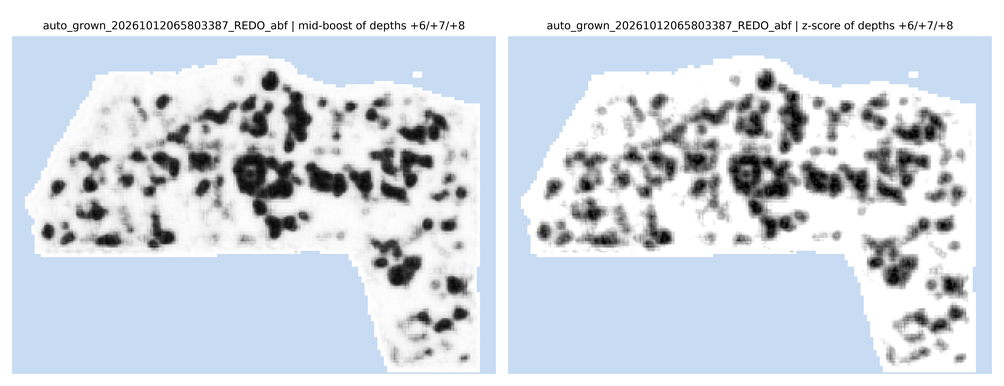

Saved /vesuvius/output/REDO/runs_iter2_iter2_asf_cue_model_epoch_10/offset_-1/auto_grown_20261012065803387_REDO_abf_combo_d+6_+8.png


In [14]:
# mid-boost | z-score combinations of the depth +6, +7 and +8 predictions (each with its own window's cue), base sheet only
import utils.depth_ensemble as depth_ensemble_utils

importlib.reload(depth_ensemble_utils)
COMBO_SHIFTS = (6, 7, 8)
COMBO_METHODS = ("mid-boost", "z-score")
COMBO_NAMES = (REDO,)


def render_combination(name, preview=True):
    inputs = load_inputs(name)
    stack = np.stack([depth_prediction(inputs, name, shift) for shift in COMBO_SHIFTS])
    depths = "/".join(f"{shift:+d}" for shift in COMBO_SHIFTS)
    panels = [[
        (f"{name} | {method} of depths {depths}",
         colorize(orient_display(depth_ensemble_utils.combine(stack, method), name), "gray_r", (0.78, 0.86, 0.95)),
         cv2.INTER_NEAREST, None)
        for method in COMBO_METHODS
    ]]
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    output_path = OUT_DIR / f"{name}_combo_d{COMBO_SHIFTS[0]:+d}_{COMBO_SHIFTS[-1]:+d}.png"
    save_panel_grid(panels, inputs["mask"].shape, str(output_path), gap_px=24)
    if preview:
        with Image.open(output_path) as saved:
            display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE),
                                  max(1, saved.height // PREVIEW_DOWNSCALE)), Image.Resampling.LANCZOS))
    print(f"Saved {output_path}")
    del inputs, stack, panels
    gc.collect()
    return output_path


for combo_name in COMBO_NAMES:
    render_combination(combo_name)
